# Línea de transferencia: el modelo de TCT_Proyect y su programa para OpenPLC

[![Abrir en Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/nebisman/deslab-py3/blob/main/notebooks/factory_io/LCS_modular_control_transfer_line_openplc.ipynb)

La escena es la línea de transferencia de Factory I/O (`Transfer_line.factoryio`, en la carpeta
`Factory scenes`). La estación $M_1$ entrega piezas a una cinta que hace de buffer $B_1$; allí un
posicionador las sujeta y una cuchilla de tope las deja pasar a la máquina $M_2$, un centro de
mecanizado. Lo que termina $M_2$ pasa por una cinta corta ($B_2$) a la unidad de prueba $TU$, donde
un sensor de visión acepta la pieza o la rechaza. Una pieza aceptada sale de la línea; una
rechazada se desvía y un pick & place de dos ejes la devuelve a $B_1$ para reprocesarla.

Este notebook es la versión DESlab del script `Transfer_line.py` de TCT_Proyect, que usaba TCT:
tiene los mismos autómatas, especificaciones y mapa de señales, definidos directamente con `fsa`
y solo con los autolazos que hacen falta. Hay dos supervisores para la línea, que resultan
conflictivos: `generate_ST_OPENPLC` detecta el conflicto, sintetiza un coordinador y lo incluye en
el programa en texto estructurado (ST) para OpenPLC. El programa es igual, byte por byte, al
`transfer_line.st` que genera TCT con ese script, salvo los comentarios que agrega DESlab y el
nombre del programa: DESlab lo llama `supcon` y TCT `tesis0` (sección 6).

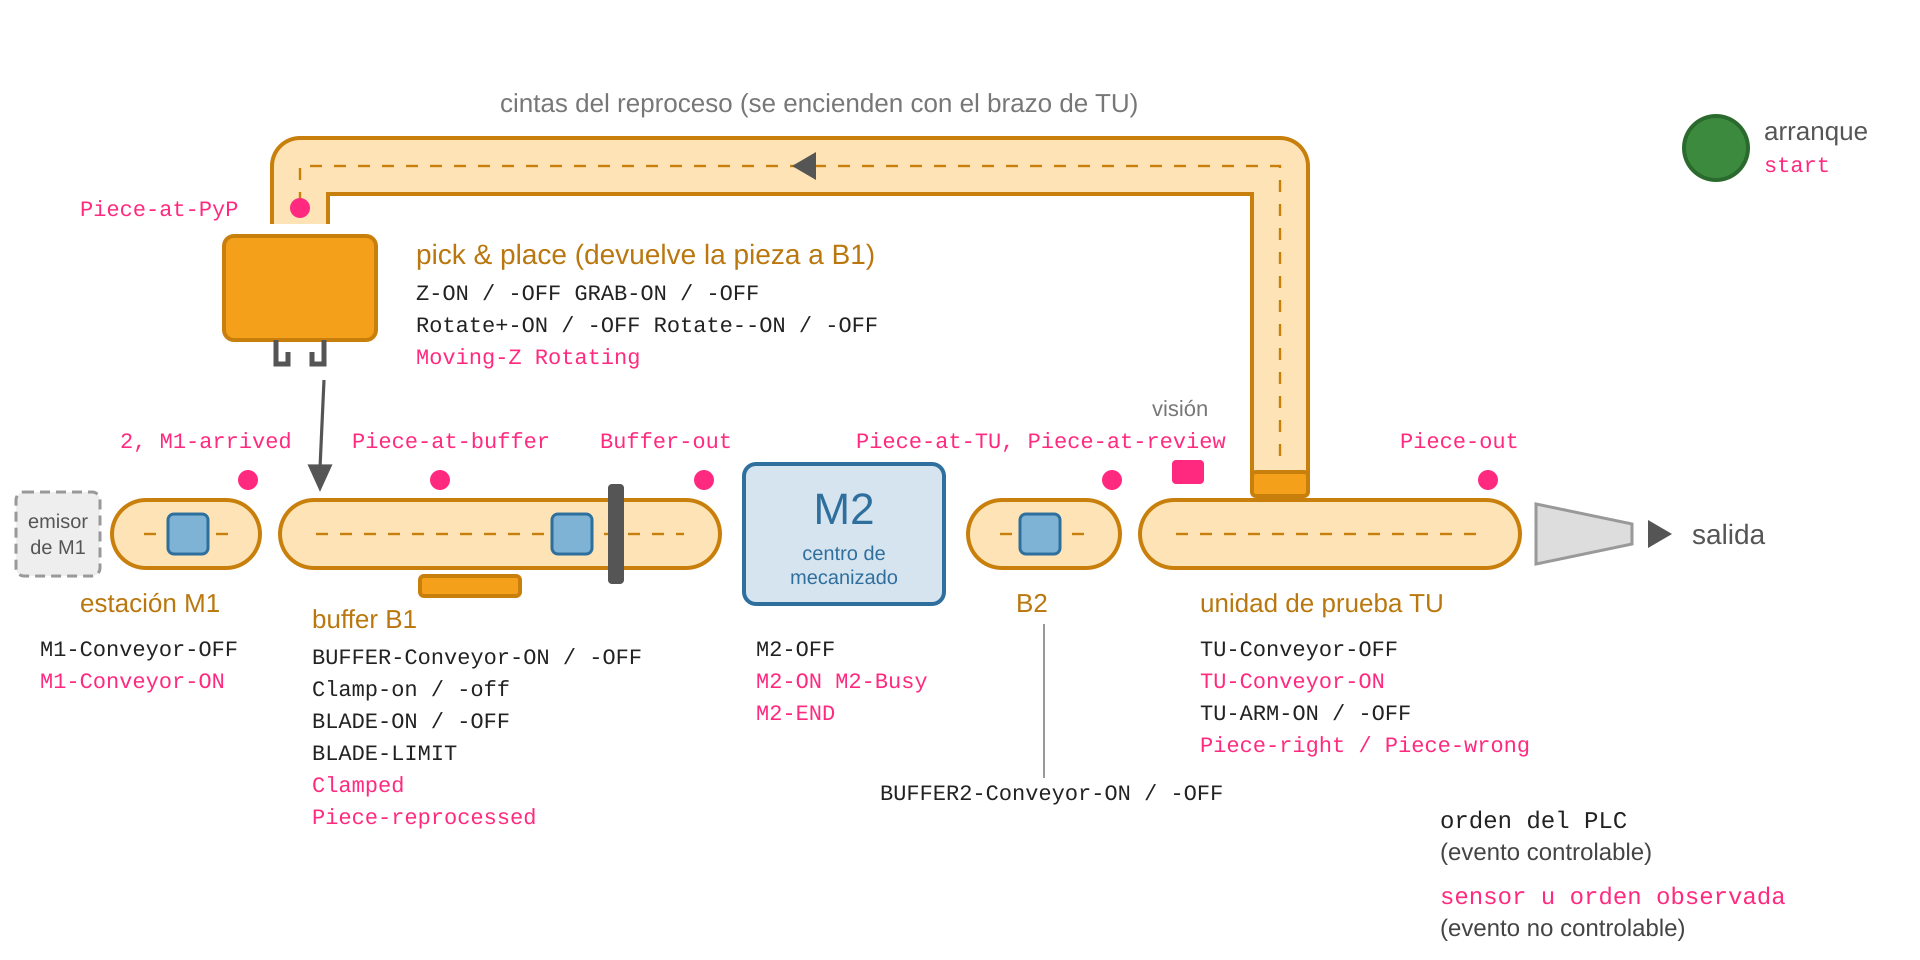

In [ ]:
#@title Instalación de DESlab desde GitHub (ejecute esta celda primero)
import importlib, json, shutil, subprocess, sys
from importlib.metadata import distribution

# programas de graphviz (Colab normalmente ya los trae instalados)
if shutil.which("dot") is None:
    subprocess.run("apt-get -qq install -y graphviz > /dev/null", shell=True)

%pip install -q networkx graphviz
# se reinstala siempre la última versión de DESlab que está en GitHub
%pip install -q --force-reinstall --no-deps --no-cache-dir git+https://github.com/nebisman/deslab-py3.git

# si la celda se ejecuta de nuevo, DESlab se descarga de la memoria para
# que la siguiente celda importe la versión recién instalada
importlib.invalidate_caches()
for name in [m for m in sys.modules if m == "deslab" or m.startswith("deslab.")]:
    del sys.modules[name]

info = json.loads(distribution("deslab").read_text("direct_url.json") or "{}")
print("DESlab instalado desde el commit", info.get("vcs_info", {}).get("commit_id", "?")[:7])

In [1]:
from deslab import *

## 1. Eventos

Se conservan los nombres del script original (incluido `Camp_REQ`), con guiones en lugar de `_`
(DESlab dibuja lo que sigue a `_` como subíndice) y con `Busy` donde el script escribe `Bussy`.
`1`, `3` y `5` son las peticiones de los
supervisores para arrancar $M_1$, $M_2$ y $TU$, y `2` es la llegada de una pieza de $M_1$ a $B_1$.

| Parte | Controlables | No controlables |
|---|---|---|
| estación $M_1$ | `M1-Conveyor-OFF` | `M1-Conveyor-ON` (la orden está encendida), `2` (la pieza llega al sensor de salida, flanco de subida), `M1-arrived` (la pieza deja el sensor, flanco de bajada) |
| buffer $B_1$ | `BUFFER-Conveyor-ON`, `BUFFER-Conveyor-OFF`, `Clamp-on`, `Clamp-off`, `BLADE-ON`, `BLADE-OFF`, `BLADE-LIMIT` | `Piece-at-buffer` (pieza en el posicionador), `Clamped` (pieza sujeta), `Buffer-out` (la pieza salió de $B_1$), `Piece-reprocessed` (volvió una pieza rechazada) |
| máquina $M_2$ | `M2-OFF` | `M2-ON`, `M2-Busy` (ocupada), `M2-END` (terminó) |
| buffer $B_2$ | `BUFFER2-Conveyor-ON`, `BUFFER2-Conveyor-OFF` | `Piece-at-TU` (la pieza llega a la entrada de $TU$) |
| unidad de prueba $TU$ | `TU-Conveyor-OFF`, `TU-ARM-ON`, `TU-ARM-OFF` | `TU-Conveyor-ON`, `Piece-at-review` (la pieza pasó a revisión), `Piece-right` y `Piece-wrong` (el sensor de visión la acepta o la rechaza), `Piece-out` (salió de la línea), `Piece-at-PyP` (llegó al pick & place) |
| pick & place | `Z-ON`, `Z-OFF`, `GRAB-ON`, `GRAB-OFF`, `Rotate+-ON`, `Rotate+-OFF`, `Rotate--ON`, `Rotate--OFF` | `Moving-Z`, `Rotating` (fin de cada movimiento) |
| tablero | | `start` (pulsador de arranque) |
| peticiones de los supervisores | `1`, `3`, `5` | |

Como en el script, `M1-Conveyor-ON`, `M2-ON` y `TU-Conveyor-ON` no son controlables: la orden la
enciende la petición del supervisor (sección 5) y los autómatas solo observan que está encendida.
`BLADE-LIMIT`, el fin de carrera de la cuchilla, es una entrada, pero el script lo declara
controlable; se conserva así para obtener el mismo programa (vea la advertencia de la sección 7).

TCT numeraba los eventos controlables con números impares y los no controlables con pares, en el
orden en que el script los declara. Las listas siguen ese orden, que se usa al final para escribir
el programa como TCT.

In [2]:
# en el orden en que Transfer_line.py declara los eventos
CONTROLABLES = ['M1-Conveyor-OFF', 'Clamp-on', 'Clamp-off', 'BLADE-ON', 'BLADE-OFF',
                'BUFFER-Conveyor-ON', 'BUFFER-Conveyor-OFF', 'BLADE-LIMIT', 'M2-OFF',
                'BUFFER2-Conveyor-ON', 'BUFFER2-Conveyor-OFF', 'Z-ON', 'GRAB-ON', 'Z-OFF',
                'Rotate+-ON', 'Rotate+-OFF', 'GRAB-OFF', 'Rotate--ON', 'Rotate--OFF',
                'TU-Conveyor-OFF', 'TU-ARM-ON', 'TU-ARM-OFF', '1', '3', '5']
NO_CONTROLABLES = ['M1-Conveyor-ON', 'M1-arrived', 'Clamped', 'Piece-at-buffer', 'Buffer-out', '2',
                   'Piece-reprocessed', 'M2-ON', 'M2-Busy', 'M2-END', 'Piece-at-TU', 'Piece-at-PyP',
                   'Moving-Z', 'Rotating', 'TU-Conveyor-ON', 'Piece-at-review', 'Piece-right',
                   'Piece-out', 'Piece-wrong', 'start']

## 2. Supervisores locales de las estaciones

Cuatro supervisores locales manejan los actuadores de cada estación. Igual que en el script, no van
en la lista de supervisores del programa sino entre los autómatas auxiliares (sección 4).

| Supervisor | Planta | Especificación | Qué pide |
|---|---|---|---|
| `sup_M1` | `Conveyor_M1` | `M1_piece` | apagar la cinta de $M_1$ cuando la pieza deja el sensor de salida |
| `sup_B1` | `Conveyor_buffer` $\parallel$ `Clamp` $\parallel$ `Blade` | `event_2` $\parallel$ `Buffer_join` $\parallel$ `Camp_REQ` | con una pieza nueva (`2` o `Piece-reprocessed`), mover la cinta hasta el posicionador, sujetarla y soltarla, accionar la cuchilla y mover la cinta hasta que la pieza sale de $B_1$; la pinza se suelta solo después de `Clamped` |
| `sup_B2` | `Conveyor_buffer2` | `Buffer2_join` | cuando $M_2$ termina, mover la cinta de $B_2$ hasta que la pieza llega a $TU$ |
| `sup_TU` | `Conveyor_TU` $\parallel$ `ARM_TU` | `TU_Function` | con la cinta encendida, esperar la revisión; si la pieza es buena, apagar la cinta cuando sale; si es mala, desviarla con el brazo hasta el pick & place |

**Sensores compartidos.** Un sensor que usa una especificación tiene que estar en la planta de su
supervisor como evento no controlable. Si no está, la planta no lo genera y el supervisor nunca lo
deja ocurrir. Por eso cada cinta lleva como autolazos, en sus dos estados, los sensores que usan
sus especificaciones: la planta no restringe cuándo llegan. La pinza lleva `Clamped` y la cuchilla
`BLADE-LIMIT`.

**Autolazos de las especificaciones.** En una especificación, un sensor del alfabeto que no está
definido en un estado queda prohibido allí; si la planta puede generarlo, el supervisor tiene que
evitar ese estado. Cada especificación lleva el autolazo de cada sensor en los estados donde no lo
espera. La excepción es `TU-Conveyor-ON` en `TU_Function`: el script le ponía autolazos en los
estados 1 a 8, pero allí la cinta ya está encendida y la planta no puede generar ese evento. No
hacen falta: sin ellos el supervisor y el programa son los mismos.

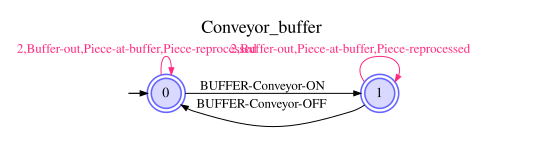

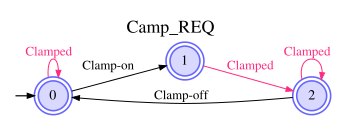

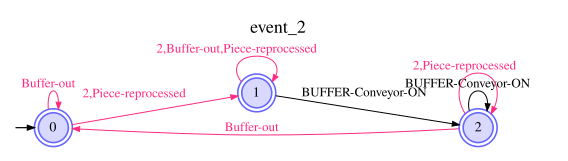

In [3]:
# plantas: cada cinta lleva como autolazos los sensores que usan sus especificaciones
Conveyor_M1 = fsa([0, 1], ['M1-Conveyor-ON', 'M1-Conveyor-OFF', 'M1-arrived'],
                  [(0, 'M1-Conveyor-ON', 1), (1, 'M1-Conveyor-OFF', 0),
                   (0, 'M1-arrived', 0), (1, 'M1-arrived', 1)],
                  [0], [0, 1], Sigcon=['M1-Conveyor-OFF'], name='Conveyor_M1')
Clamp = fsa([0, 1], ['Clamp-on', 'Clamp-off', 'Clamped'],
            [(0, 'Clamp-on', 1), (1, 'Clamp-off', 0),
             (0, 'Clamped', 0), (1, 'Clamped', 1)],
            [0], [0, 1], Sigcon=['Clamp-on', 'Clamp-off'], name='Clamp')
Blade = fsa([0, 1], ['BLADE-ON', 'BLADE-OFF', 'BLADE-LIMIT'],
            [(0, 'BLADE-ON', 1), (1, 'BLADE-OFF', 0),
             (0, 'BLADE-LIMIT', 0), (1, 'BLADE-LIMIT', 1)],
            [0], [0, 1], Sigcon=['BLADE-ON', 'BLADE-OFF', 'BLADE-LIMIT'], name='Blade')
sensores_b1 = ['Piece-at-buffer', 'Buffer-out', '2', 'Piece-reprocessed']
Conveyor_buffer = fsa([0, 1], ['BUFFER-Conveyor-ON', 'BUFFER-Conveyor-OFF'] + sensores_b1,
                      [(0, 'BUFFER-Conveyor-ON', 1), (1, 'BUFFER-Conveyor-OFF', 0)]
                      + [(x, e, x) for x in (0, 1) for e in sensores_b1],
                      [0], [0, 1], Sigcon=['BUFFER-Conveyor-ON', 'BUFFER-Conveyor-OFF'],
                      name='Conveyor_buffer')
sensores_b2 = ['M2-END', 'M2-Busy', 'Piece-at-TU']
Conveyor_buffer2 = fsa([0, 1], ['BUFFER2-Conveyor-ON', 'BUFFER2-Conveyor-OFF'] + sensores_b2,
                       [(0, 'BUFFER2-Conveyor-ON', 1), (1, 'BUFFER2-Conveyor-OFF', 0)]
                       + [(x, e, x) for x in (0, 1) for e in sensores_b2],
                       [0], [0, 1], Sigcon=['BUFFER2-Conveyor-ON', 'BUFFER2-Conveyor-OFF'],
                       name='Conveyor_buffer2')
sensores_tu = ['Piece-at-review', 'Piece-right', 'Piece-out', 'Piece-at-PyP', 'Piece-wrong']
Conveyor_TU = fsa([0, 1], ['TU-Conveyor-ON', 'TU-Conveyor-OFF'] + sensores_tu,
                  [(0, 'TU-Conveyor-ON', 1), (1, 'TU-Conveyor-OFF', 0)]
                  + [(x, e, x) for x in (0, 1) for e in sensores_tu],
                  [0], [0, 1], Sigcon=['TU-Conveyor-OFF'], name='Conveyor_TU')
ARM_TU = fsa([0, 1], ['TU-ARM-ON', 'TU-ARM-OFF'], [(0, 'TU-ARM-ON', 1), (1, 'TU-ARM-OFF', 0)],
             [0], [0, 1], Sigcon=['TU-ARM-ON', 'TU-ARM-OFF'], name='ARM_TU')

# especificaciones: autolazos de cada sensor donde no se espera
M1_piece = fsa([0, 1], ['M1-arrived', 'M1-Conveyor-OFF'],
               [(0, 'M1-arrived', 1), (1, 'M1-Conveyor-OFF', 0),
                (1, 'M1-arrived', 1)],
               [0], [0, 1], Sigcon=['M1-Conveyor-OFF'], name='M1_piece')
Camp_REQ = fsa([0, 1, 2], ['Clamp-on', 'Clamped', 'Clamp-off'],
               [(0, 'Clamp-on', 1), (1, 'Clamped', 2), (2, 'Clamp-off', 0),
                (0, 'Clamped', 0), (2, 'Clamped', 2)],
               [0], [0, 1, 2], Sigcon=['Clamp-on', 'Clamp-off'], name='Camp_REQ')
Buffer_join = fsa(list(range(12)),
                  ['BUFFER-Conveyor-ON', 'Piece-at-buffer', 'BUFFER-Conveyor-OFF', 'Clamp-on', 'Clamp-off',
                   'BLADE-ON', 'BLADE-LIMIT', 'Buffer-out', 'BLADE-OFF'],
                  [(0, 'BUFFER-Conveyor-ON', 1), (1, 'Piece-at-buffer', 2), (2, 'BUFFER-Conveyor-OFF', 3),
                   (3, 'Clamp-on', 4), (4, 'Clamp-off', 5), (5, 'BLADE-ON', 6), (6, 'BLADE-LIMIT', 7),
                   (7, 'BUFFER-Conveyor-ON', 8), (8, 'Buffer-out', 9), (9, 'BUFFER-Conveyor-OFF', 10),
                   (10, 'BLADE-OFF', 11), (11, 'BLADE-LIMIT', 0)]
                  + [(x, 'Piece-at-buffer', x) for x in range(12) if x != 1]
                  + [(x, 'Buffer-out', x) for x in range(12) if x != 8],
                  [0], list(range(12)),
                  Sigcon=['BUFFER-Conveyor-ON', 'BUFFER-Conveyor-OFF', 'Clamp-on', 'Clamp-off',
                          'BLADE-ON', 'BLADE-OFF', 'BLADE-LIMIT'], name='Buffer_join')
event_2 = fsa([0, 1, 2], ['2', 'BUFFER-Conveyor-ON', 'Buffer-out', 'Piece-reprocessed'],
              [(0, '2', 1), (1, 'BUFFER-Conveyor-ON', 2), (2, 'Buffer-out', 0),
               (2, 'BUFFER-Conveyor-ON', 2), (0, 'Piece-reprocessed', 1),
               (0, 'Buffer-out', 0), (1, 'Buffer-out', 1), (1, '2', 1), (2, '2', 2),
               (1, 'Piece-reprocessed', 1), (2, 'Piece-reprocessed', 2)],
              [0], [0, 1, 2], Sigcon=['BUFFER-Conveyor-ON'], name='event_2')
Buffer2_join = fsa(list(range(5)), ['M2-Busy', 'M2-END', 'BUFFER2-Conveyor-ON', 'Piece-at-TU',
                                     'BUFFER2-Conveyor-OFF'],
                   [(0, 'M2-Busy', 1), (1, 'M2-END', 2), (2, 'BUFFER2-Conveyor-ON', 3),
                    (3, 'Piece-at-TU', 4), (4, 'BUFFER2-Conveyor-OFF', 0)]
                   + [(x, 'M2-Busy', x) for x in (1, 2, 3, 4)]
                   + [(x, 'M2-END', x) for x in (0, 2, 3, 4)]
                   + [(x, 'Piece-at-TU', x) for x in (0, 1, 2, 4)],
                   [0], list(range(5)), Sigcon=['BUFFER2-Conveyor-ON', 'BUFFER2-Conveyor-OFF'],
                   name='Buffer2_join')
# estado en el que TU_Function espera cada sensor
espera = {'Piece-at-review': 1, 'Piece-right': 2, 'Piece-wrong': 2, 'Piece-out': 3, 'Piece-at-PyP': 6}
TU_Function = fsa(list(range(9)), ['TU-Conveyor-ON', 'TU-Conveyor-OFF', 'TU-ARM-ON', 'TU-ARM-OFF'] + list(espera),
                  [(0, 'TU-Conveyor-ON', 1), (1, 'Piece-at-review', 2), (2, 'Piece-right', 3),
                   (3, 'Piece-out', 4), (4, 'TU-Conveyor-OFF', 0), (2, 'Piece-wrong', 5),
                   (5, 'TU-ARM-ON', 6), (6, 'Piece-at-PyP', 7), (7, 'TU-ARM-OFF', 8),
                   (8, 'TU-Conveyor-OFF', 0)]
                  + [(x, e, x) for e, k in espera.items() for x in range(9) if x != k],
                  [0], list(range(9)), Sigcon=['TU-Conveyor-OFF', 'TU-ARM-ON', 'TU-ARM-OFF'],
                  name='TU_Function')
draw(Conveyor_buffer, Camp_REQ, event_2)

Cada supervisor local es `supcontrollable(G // E, G)` con su planta $G$ y su especificación $E$. En
TCT la especificación se sincronizaba también con todos los eventos de la planta (`allm1`,
`allb1`, ...); en DESlab no hace falta, porque la composición paralela deja libres los eventos de
la planta que la especificación no tiene. Los cuatro tienen los mismos estados y transiciones que
los que calculaba TCT.

supervisor | estados | transiciones
  sup_M1   |       4 |            7
  sup_B1   |      33 |          189
  sup_B2   |       5 |           17
  sup_TU   |       9 |           50


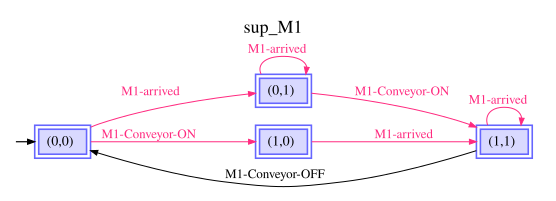

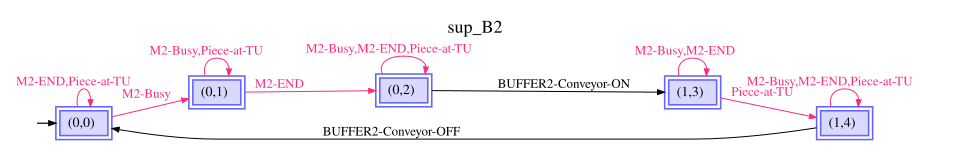

In [4]:
def local(planta, especificacion, nombre):
    return supcontrollable(planta // especificacion, planta).setpar(name=nombre, style='rectangle')

P_B1 = Conveyor_buffer // Clamp // Blade
P_TU = Conveyor_TU // ARM_TU
sup_M1 = local(Conveyor_M1, M1_piece, 'sup_M1')
sup_B1 = local(P_B1, event_2 // Buffer_join // Camp_REQ, 'sup_B1')
sup_B2 = local(Conveyor_buffer2, Buffer2_join, 'sup_B2')
sup_TU = local(P_TU, TU_Function, 'sup_TU')

print('supervisor | estados | transiciones')
for S in (sup_M1, sup_B1, sup_B2, sup_TU):
    print(f'  {S.name:8} | {len(S):7} | {sum(len(S.Gamma(x)) for x in S.X):12}')
draw(sup_M1, sup_B2)

## 3. Los supervisores de la línea

Los dos supervisores principales ven cada estación como un modelo abstracto de dos estados:
`M1_REQ` (la petición `1` y la llegada de la pieza a $B_1$, `2`), `M2_REQ` (la petición `3` y la
llegada de la pieza a $TU$) y `TU_REQ` (la petición `5` y la salida de la pieza, aceptada
`Piece-out` o devuelta a $B_1$ `Piece-reprocessed`). Solo el estado 0 es marcado.

| Supervisor | Planta | Especificación | Qué pide |
|---|---|---|---|
| `sup_2` | `M1_REQ` $\parallel$ `M2_REQ` $\parallel$ `TU_REQ` | `start` $\parallel$ `B1SP` | ninguna petición antes del arranque; $B_1$ guarda una pieza, que llega de $M_1$ o del reproceso y sale con la petición `3` |
| `sup2_2` | `M2_REQ` $\parallel$ `TU_REQ` | `B2SP` | $B_2$ guarda una pieza, que llega con `Piece-at-TU` y sale con la petición `5` |

El pulsador `start` lo usa la especificación `start`: `M2_REQ` lo lleva como autolazo en sus dos
estados y `start` en su estado marcado, 1. Los dos supervisores tienen los mismos estados y
transiciones que en TCT. Son controlables pero conflictivos: juntos pueden llegar a un estado desde
el que no se alcanza un estado marcado.

sup_2: 9 estados, 24 transiciones
sup2_2: 6 estados, 17 transiciones
¿sup_2 y sup2_2 son no conflictivos? False


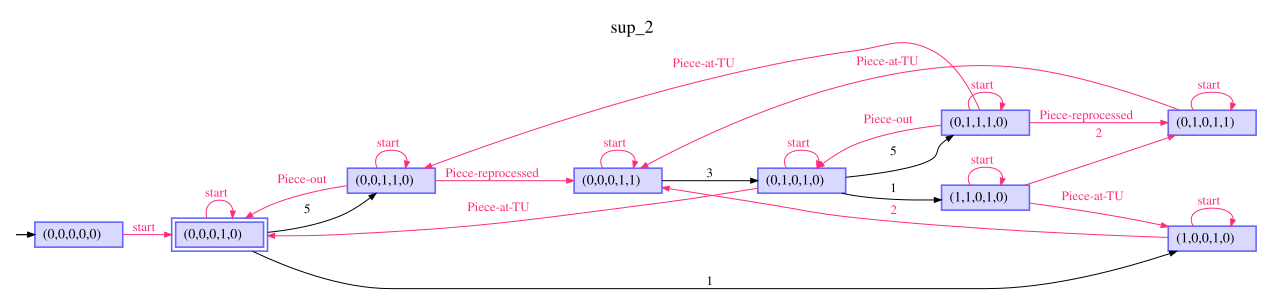

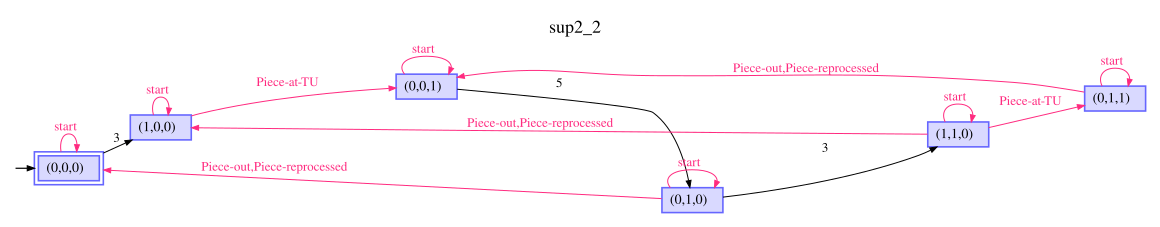

In [5]:
M1_REQ = fsa([0, 1], ['1', '2'], [(0, '1', 1), (1, '2', 0)], [0], [0], Sigcon=['1'], name='M1_REQ')
M2_REQ = fsa([0, 1], ['3', 'Piece-at-TU', 'start'],
             [(0, '3', 1), (1, 'Piece-at-TU', 0),
              (0, 'start', 0), (1, 'start', 1)],
             [0], [0], Sigcon=['3'], name='M2_REQ')
TU_REQ = fsa([0, 1], ['5', 'Piece-out', 'Piece-reprocessed'],
             [(0, '5', 1), (1, 'Piece-out', 0), (1, 'Piece-reprocessed', 0)],
             [0], [0], Sigcon=['5'], name='TU_REQ')
B1SP = fsa([0, 1], ['2', 'Piece-reprocessed', '3'],
           [(0, '2', 1), (0, 'Piece-reprocessed', 1), (1, '3', 0)],
           [0], [0], Sigcon=['3'], name='B1SP')
B2SP = fsa([0, 1], ['Piece-at-TU', '5'], [(0, 'Piece-at-TU', 1), (1, '5', 0)],
           [0], [0], Sigcon=['5'], name='B2SP')
start = fsa([0, 1], ['start', '1', '3', '5'],
            [(0, 'start', 1), (1, '1', 1), (1, '3', 1), (1, '5', 1),
             (1, 'start', 1)],
            [0], [1], Sigcon=['1', '3', '5'], name='start')

plant_2 = M1_REQ // M2_REQ // TU_REQ
plant2_2 = M2_REQ // TU_REQ
sup_2 = supcontrollable(plant_2 // start // B1SP, plant_2).setpar(name='sup_2', style='rectangle')
sup2_2 = supcontrollable(plant2_2 // B2SP, plant2_2).setpar(name='sup2_2', style='rectangle')
assert iscontrollable(sup_2, plant_2) and iscontrollable(sup2_2, plant2_2)
for S in (sup_2, sup2_2):
    print(f'{S.name}: {len(S)} estados, {sum(len(S.Gamma(x)) for x in S.X)} transiciones')
print('¿sup_2 y sup2_2 son no conflictivos?', nonconflict(sup_2, sup2_2))
draw(sup_2, sup2_2)

## 4. Autómatas auxiliares

Los autómatas auxiliares van en el parámetro `Isolated` de `generate_ST_OPENPLC`: cada uno tiene su propio
estado en el programa, escribe las salidas de sus eventos controlables y avanza con sus eventos no
controlables, pero no participa en la coordinación. Son los cuatro supervisores locales y dos
secuencias:

* `M2`: cuando $M_2$ confirma el arranque (`M2-Busy`), apaga la orden (`M2-OFF`) y espera el fin
  (`M2-END`);
* `Pyp`: con una pieza rechazada en su posición (`Piece-at-PyP`), el pick & place baja, la toma,
  sube, gira, baja, la suelta en $B_1$, sube y vuelve a girar; espera el fin de cada movimiento
  (`Moving-Z`, `Rotating`).

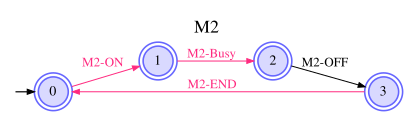

In [6]:
M2 = fsa([0, 1, 2, 3], ['M2-ON', 'M2-Busy', 'M2-OFF', 'M2-END'],
         [(0, 'M2-ON', 1), (1, 'M2-Busy', 2), (2, 'M2-OFF', 3), (3, 'M2-END', 0)],
         [0], [0, 1, 2, 3], Sigcon=['M2-OFF'], name='M2')
secuencia = ['Piece-at-PyP', 'Z-ON', 'Moving-Z', 'GRAB-ON', 'Z-OFF', 'Moving-Z', 'Rotate+-ON', 'Rotating',
             'Rotate+-OFF', 'Z-ON', 'Moving-Z', 'GRAB-OFF', 'Z-OFF', 'Moving-Z', 'Rotate--ON', 'Rotating',
             'Rotate--OFF']
Pyp = fsa(list(range(17)), set(secuencia), [(k, e, (k + 1) % 17) for k, e in enumerate(secuencia)],
          [0], list(range(17)),
          Sigcon=['Z-ON', 'GRAB-ON', 'Z-OFF', 'Rotate+-ON', 'Rotate+-OFF', 'GRAB-OFF', 'Rotate--ON',
                  'Rotate--OFF'], name='Pyp')

auxiliares = [sup_M1, sup_B1, M2, sup_B2, sup_TU, Pyp]
draw(M2)

## 5. Mapa de señales

Es el mapa del script original, en el mismo orden: el orden de las declaraciones del programa sale
de él. Las claves son los eventos, con guiones; las variables del PLC conservan `_` porque en ST un
identificador no puede tener guiones.

| Formato | Significado | Ejemplo |
|---|---|---|
| `Variable:ON:dirección`, `Variable:OFF[:dirección]` | escribe 1 o 0 en una salida; en una entrada, observa el nivel 1 o 0 | `'M2-ON': 'GD_OUT_7:ON:%QX100.7'`, `'Piece-wrong': 'GD_IN_8:OFF'` |
| `RE_Nombre:Entrada:dirección`, `FE_...` | flanco de subida (`R_TRIG`) o de bajada (`F_TRIG`) de una entrada | `'2': 'RE_M1:GD_IN_1:%IX100.1'` |
| `INTERN_k:ON` | variable interna del programa | `'1': 'INTERN_1:ON'` |

Las peticiones `1`, `3` y `5` son variables internas: las **parejas** del parámetro `event_pairs`
las convierten en órdenes. La pareja `('3', 'M2-ON')` pone `GD_OUT_7 = 1` cuando sube `INTERN_3` y, con
la orden ya encendida, borra la petición; el autómata auxiliar `M2` apaga la orden después.

`Masks` copia en cada scan una salida en otras: la cinta de $M_1$ (`GD_OUT_0`) enciende también su
emisor y su brazo (`GD_OUT_1` a `GD_OUT_3`), y el brazo de $TU$ (`GD_OUT_10`) enciende la velocidad
del brazo, las cintas del reproceso y su emisor (`GD_OUT_11` a `GD_OUT_14`).

In [7]:
actuators = {
    'start': 'GD_IN_0:ON:%IX100.0', 'Piece-right': 'GD_IN_8:ON:%IX101.0',
    '2': 'RE_M1:GD_IN_1:%IX100.1', 'M2-END': 'FE_M2E:GD_IN_6:%IX100.6',
    'M2-ON': 'GD_OUT_7:ON:%QX100.7', 'M2-OFF': 'GD_OUT_7:OFF', 'M2-Busy': 'GD_IN_6:ON:%IX100.6',
    'Piece-at-review': 'FE_CP:GD_IN_7:%IX100.7', 'Piece-at-TU': 'RE_CP:GD_IN_7:%IX100.7',
    'M1-arrived': 'FE_M1:GD_IN_1:%IX100.1',
    'Clamp-on': 'GD_OUT_4:ON:%QX100.4', 'Clamp-off': 'GD_OUT_4:OFF', 'Clamped': 'GD_IN_2:ON:%IX100.2',
    'Piece-at-buffer': 'FE_B1:GD_IN_3:%IX100.3',
    'BUFFER-Conveyor-ON': 'GD_OUT_5:ON:%QX100.5', 'BUFFER-Conveyor-OFF': 'GD_OUT_5:OFF',
    'BLADE-ON': 'GD_OUT_6:ON:%QX100.6', 'BLADE-OFF': 'GD_OUT_6:OFF', 'BLADE-LIMIT': 'GD_IN_4:ON:%IX100.4',
    'Buffer-out': 'FE_B1O:GD_IN_5:%IX100.5',
    'BUFFER2-Conveyor-ON': 'GD_OUT_8:ON:%QX101.0', 'BUFFER2-Conveyor-OFF': 'GD_OUT_8:OFF',
    'TU-Conveyor-ON': 'GD_OUT_9:ON:%QX101.1', 'TU-Conveyor-OFF': 'GD_OUT_9:OFF',
    'TU-ARM-ON': 'GD_OUT_10:ON:%QX101.2', 'TU-ARM-OFF': 'GD_OUT_10:OFF',
    'Piece-wrong': 'GD_IN_8:OFF', 'Piece-out': 'FE_PO:GD_IN_9:%IX101.1',
    'Piece-reprocessed': 'FE_PR:GD_IN_11:%IX101.3', 'Piece-at-PyP': 'FE_AT:GD_IN_10:%IX101.2',
    'Moving-Z': 'FE_MZ:GD_IN_12:%IX101.4', 'Rotating': 'FE_RO:GD_IN_13:%IX101.5',
    'Z-ON': 'GD_OUT_15:ON:%QX101.7', 'Z-OFF': 'GD_OUT_15:OFF',
    'GRAB-ON': 'GD_OUT_18:ON:%QX102.2', 'GRAB-OFF': 'GD_OUT_18:OFF',
    'Rotate+-ON': 'GD_OUT_16:ON:%QX102.0', 'Rotate+-OFF': 'GD_OUT_16:OFF',
    'Rotate--ON': 'GD_OUT_17:ON:%QX102.1', 'Rotate--OFF': 'GD_OUT_17:OFF',
    '1': 'INTERN_1:ON', '3': 'INTERN_3:ON', '5': 'INTERN_5:ON',
    'M1-Conveyor-ON': 'GD_OUT_0:ON:%QX100.0', 'M1-Conveyor-OFF': 'GD_OUT_0:OFF',
}
Masks = {'GD_OUT_0': [('GD_OUT_1', '%QX100.1'), ('GD_OUT_2', '%QX100.2'), ('GD_OUT_3', '%QX100.3')],
         'GD_OUT_10': [('GD_OUT_11', '%QX101.3'), ('GD_OUT_12', '%QX101.4'),
                       ('GD_OUT_13', '%QX101.5'), ('GD_OUT_14', '%QX101.6')]}
parejas = [('1', 'M1-Conveyor-ON'), ('3', 'M2-ON'), ('5', 'TU-Conveyor-ON')]

## 6. Generar el programa y su coordinador

| Parámetro | Valor |
|---|---|
| `supervisors`, `plants` | `[sup_2, sup2_2]` y `[plant_2, plant2_2]`: una planta por supervisor; con ellas se busca el conflicto y se sintetiza el coordinador |
| `Isolated` | `auxiliares` |
| `event_pairs` | `parejas`: convierten las peticiones `1`, `3` y `5` en órdenes |
| `initial` | `'start'`: el programa espera el pulsador de arranque antes de empezar |
| `event_order` | los eventos ordenados por el número que les daba TCT |

El generador revisa el par `sup_2`, `sup2_2`, encuentra el conflicto y sintetiza un coordinador
con `sup_2` $\parallel$ `sup2_2` como planta; después lo reduce y conserva solo lo necesario para
decidir qué peticiones deshabilitar. Como en TCT, el coordinador tiene su propia variable de estado
y, para cada petición, una bandera `INTERN_k_C[1]` que vale 1 en los estados donde la permite.

Aquí no hace falta `state_order` ni `transition_order` (vea el notebook de la pequeña fábrica): en
todos los autómatas, la búsqueda en anchura del generador numera los estados como TCT.

**Dos programas de TCT.** El generador de TCT_Proyect recorre las peticiones que comparten los dos
supervisores en el orden de un conjunto (`set`) de Python, que cambia con la semilla de hash
(`PYTHONHASHSEED`) de cada ejecución. Por eso TCT genera dos programas que solo difieren en el orden
de la declaración `INTERN_5_G` y de su bloque de coordinación, que no dependen uno del otro. DESlab
las recorre ordenadas, y su programa es el que genera TCT, por ejemplo, con `PYTHONHASHSEED=2`. En
`Transfer_line.py` la llamada a `generate_ST_OPENPLC` está dentro de un comentario `"""`; para
generar el programa con TCT hay que sacarla del comentario y quitar las llamadas a
`plot_automatas`.

In [8]:
import hashlib
import re
from pathlib import Path

codigo = {e: 2 * k + 1 for k, e in enumerate(CONTROLABLES)}
codigo.update({e: 2 * k for k, e in enumerate(NO_CONTROLABLES)})
orden_eventos = sorted(codigo, key=codigo.get)

carpeta = Path('ST_Generated')
st = generate_ST_OPENPLC([sup_2, sup2_2], plants=[plant_2, plant2_2], actuators=actuators,
                         namest='transfer_line', Mask=Masks, Isolated=auxiliares,
                         initial='start', output_dir=carpeta, event_pairs=parejas,
                         event_order=orden_eventos)
archivo = carpeta / 'transfer_line.st'
assert archivo.read_text(encoding='utf-8') == st
assert 'aux : BOOL := 0;' in st                  # el programa tiene coordinador
print('programa guardado en', archivo)
print('líneas:', len(st.splitlines()))

# huella SHA-256 del transfer_line.st que genera TCT con Transfer_line.py y PYTHONHASHSEED=2
TCT = 'fd43dd2a774fb4144f180e979153a34896969d0e77fdd498129cc106d6a26fcb'
# TCT no escribe comentarios ni el retardo de arranque y llama tesis0 al programa; DESlab, supcon
sin_comentarios = re.sub(r'(?m)^[ \t]*\(\*.*\*\)\n| \(\*.*?\*\)$', '', st)
for arranque in ('\t\tstartup_delay : TON;\n',
                 '\tstartup_delay(IN := TRUE, PT := T#1s);\n\tIF NOT startup_delay.Q THEN\n\t\tRETURN;\n\tEND_IF;\n'):
    sin_comentarios = sin_comentarios.replace(arranque, '')
como_tct = sin_comentarios.replace('PROGRAM supcon', 'PROGRAM tesis0').replace(': supcon;', ': tesis0;')
print('¿igual al programa de TCT?', hashlib.sha256(como_tct.encode('utf-8')).hexdigest() == TCT)

# el coordinador es el bloque CASE que escribe las banderas _C
peticion = {v.split(':')[0]: e for e, v in actuators.items() if v.startswith('INTERN')}
k, cuerpo = next((k, c) for k, c in re.findall(r'CASE state\[(\d+)\] OF\n(.*?)END_CASE;', st, re.S)
                 if '_C[' in c)
print(f'\ncoordinador (state[{k}]):')
for estado, texto in re.findall(r'(\d+):\n(.*?)(?=\n\s*\d+:\n|\Z)', cuerpo, re.S):
    permite = [peticion[s] for s, v in re.findall(r'(INTERN_\d+)_C\[1\] := (\d)', texto) if v == '1']
    print(f'   en el estado {estado} permite las peticiones {permite}')

programa guardado en ST_Generated/transfer_line.st
líneas: 691
¿igual al programa de TCT? True

coordinador (state[8]):
   en el estado 0 permite las peticiones ['1', '3']
   en el estado 1 permite las peticiones ['5']


El coordinador tiene dos estados. En el 0 permite las peticiones de $M_1$ (`1`) y de $M_2$ (`3`);
con una petición de $M_2$ pasa al estado 1, donde solo permite la de $TU$ (`5`), y con ella vuelve
al 0. Así no se pide otra pieza a $M_1$ ni a $M_2$ hasta que $TU$ tome la pieza que entregó $M_2$, y
los dos supervisores ya no llegan al estado de bloqueo.

In [9]:
print(st)
# en Colab se descarga el archivo; en Jupyter queda un enlace
try:
    from google.colab import files
    files.download(str(archivo))
except ImportError:
    from IPython.display import FileLink, display
    display(FileLink(str(archivo)))

(* OpenPLC random number (C code), used to pick one of several orders *)
FUNCTION_BLOCK random_number
	VAR_INPUT
		IN : BOOL;
	END_VAR
	VAR
		M : BOOL;
		INIT : BOOL;
	END_VAR
	VAR_OUTPUT
		OUT : DINT;
	END_VAR

	IF INIT = 0 THEN
		{#include <stdio.h>}
		{#include <stdlib.h>}
		IN := 1;
	END_IF;
	IF M = 0 and IN = 1 THEN
		{SetFbVar(OUT,rand())}
	END_IF;
END_FUNCTION_BLOCK
(* Controller generated by DESlab (generate_ST_OPENPLC). Every scan it: *)
(* 1. computes the input edges and a random number *)
(* 2. during the first second after the PLC starts, does nothing else *)
(* 3. waits for the start signal (start); from then on it runs the next steps every scan *)
(* 4. each automaton moves with at most one uncontrollable event *)
(* 5. each automaton writes the orders enabled in its state; if there are several, it picks one at random *)
(* 6. an order shared by several supervisors changes only if all of them propose it *)
(* 7. each automaton moves with the order that was given (controll

/home/leonardo/datos/share_desktop/2026-II/Temas especiales de automatizacion/deslab/deslab-py3/notebooks/factory_io/ST_Generated/transfer_line.st

## 7. Validación y puesta en marcha

El programa generado es idéntico al `transfer_line.st` que genera TCT con `Transfer_line.py`, salvo
los comentarios, el retardo de arranque de un segundo y el nombre del programa (`supcon` en lugar
de `tesis0`): la celda de la sección 6 quita los comentarios y el retardo, cambia el nombre y
compara la huella SHA-256. La prueba `tests/test_openplc_notebooks.py` del
repositorio ejecuta las celdas de este notebook y comprueba esa huella, y además que cada autolazo
de las especificaciones es necesario y que cada sensor de una especificación está en la planta de
su supervisor.

**Advertencia sobre `BLADE-LIMIT`.** Como el script declara controlable el fin de carrera de la
cuchilla, el programa lo trata como una orden: en los estados de `sup_B1` donde espera
`BLADE-LIMIT`, el bloque `CASE` escribe `GD_IN_4 := 1` (una entrada) y en ese mismo scan avanza,
sin esperar el sensor. Para que espere el fin de carrera, pase `'BLADE-LIMIT'` a `NO_CONTROLABLES`
y quítelo de los `Sigcon` de `Blade` y `Buffer_join`; el programa deja de ser el de TCT.

Para llevarlo a OpenPLC, importe el archivo `.st`, compílelo y asigne las direcciones de la escena.
Con la línea vacía, pulse el arranque y siga una pieza por $M_1$, $B_1$, $M_2$, $B_2$ y $TU$.
Rechace una pieza en $TU$ y compruebe que el pick & place la devuelve a $B_1$ y que la línea no se
bloquea.